# 04 · Sobreajuste y regularización L2

Semana 3. Ajustamos un polinomio de grado 12 a pocos puntos y vemos cómo λ controla el sobreajuste. Evaluamos en un conjunto de validación.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(0)
plt.rcParams["figure.figsize"] = (6, 4)

In [2]:
def make_data(n):
    x = np.sort(np.random.uniform(-1, 1, n))
    return x, np.sin(3 * x) + np.random.normal(0, 0.15, n)

x_tr, y_tr = make_data(15)
x_va, y_va = make_data(200)
DEG = 12
def poly(x): return np.column_stack([x ** k for k in range(1, DEG + 1)])
Ftr, Fva = poly(x_tr), poly(x_va)
mu, sd = Ftr.mean(0), Ftr.std(0)
Ftr, Fva = (Ftr - mu) / sd, (Fva - mu) / sd

## 1. Coste y gradiente regularizados
$J_{reg} = J + \frac{\lambda}{2m}\sum_j w_j^2$ (sin regularizar $b$)

In [3]:
def cost_reg(X, y, w, b, lam):
    m = X.shape[0]
    err = X @ w + b - y
    return (err @ err) / (2 * m) + lam / (2 * m) * (w @ w)

def grad_reg(X, y, w, b, lam):
    m = X.shape[0]
    err = X @ w + b - y
    return X.T @ err / m + lam / m * w, err.mean()

def fit(X, y, lam, alpha=0.05, iters=30000):
    w, b = np.zeros(X.shape[1]), 0.0
    for _ in range(iters):
        dw, db = grad_reg(X, y, w, b, lam)
        w, b = w - alpha * dw, b - alpha * db
    return w, b

def mse(X, y, w, b): return ((X @ w + b - y) ** 2).mean()

## 2. Tres valores de λ

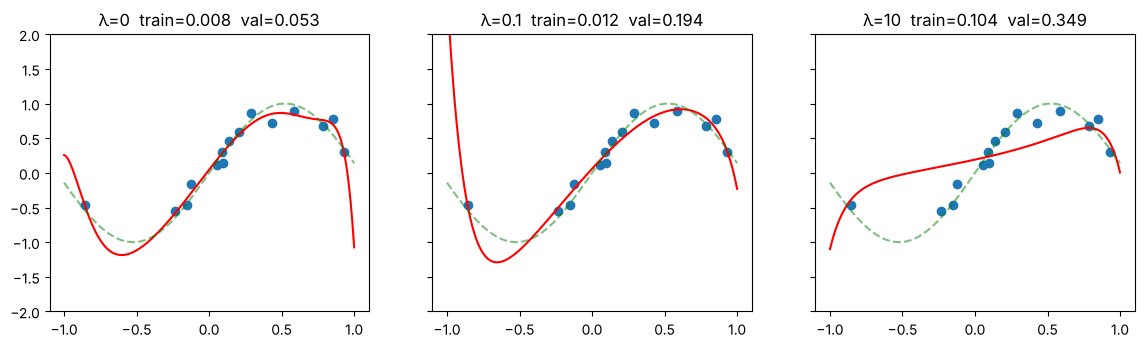

In [4]:
xs = np.linspace(-1, 1, 300)
Fs = (poly(xs) - mu) / sd
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for a, lam in zip(ax, [0, 0.1, 10]):
    w, b = fit(Ftr, y_tr, lam)
    a.scatter(x_tr, y_tr); a.plot(xs, Fs @ w + b, "r"); a.plot(xs, np.sin(3 * xs), "g--", alpha=0.5)
    a.set_ylim(-2, 2); a.set_title(f"λ={lam}  train={mse(Ftr, y_tr, w, b):.3f}  val={mse(Fva, y_va, w, b):.3f}")
plt.show()

## 3. Curva de validación: elegir λ

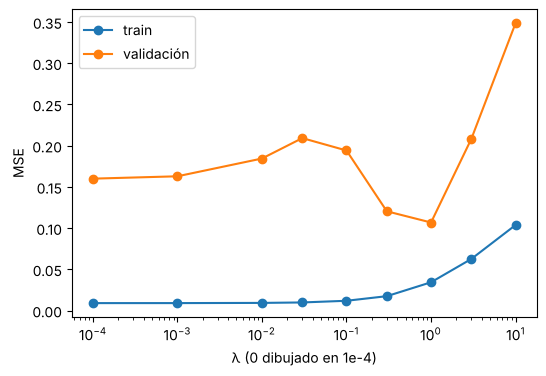

mejor λ: 1


In [5]:
lams = [0, 1e-3, 1e-2, 3e-2, 0.1, 0.3, 1, 3, 10]
tr, va = [], []
for lam in lams:
    w, b = fit(Ftr, y_tr, lam, iters=15000)
    tr.append(mse(Ftr, y_tr, w, b)); va.append(mse(Fva, y_va, w, b))
plt.semilogx([l if l else 1e-4 for l in lams], tr, "o-", label="train")
plt.semilogx([l if l else 1e-4 for l in lams], va, "o-", label="validación")
plt.xlabel("λ (0 dibujado en 1e-4)"); plt.ylabel("MSE"); plt.legend(); plt.show()
print("mejor λ:", lams[int(np.argmin(va))])

> **Para pensar:** ¿por qué el error de entrenamiento **siempre** sube con λ, pero el de validación tiene forma de U?